# Development Backtesting

## Load Backtest Inputs

- **Purpose:** Load and validate inputs for comparing three tuned meta families with one selected primary configuration; run meta modeling first. This notebook is independent of other backtesting notebooks.
- **Input:** Prepared events, split manifest, primary model, meta-model bundle, saved predictions, and market data.
- **Output:** Validated backtest inputs in memory for the following prediction, sizing, simulation, and statistics stages.
- **STRATEGY:** `sentiment_asynchronous` — Choose the matching model artifacts and execution rules.
- **PARTITION:** `development` — Use the fixed development evaluation window.
- **MANIFEST_PATH:** `data/preprocessing/universe/sp500_2025.csv` — Fix the research universe across stages.
- **DATA_START:** `2025-01-01 UTC` — Include January preparation observations before the research period.
- **RESEARCH_START:** `2025-02-01 UTC` — Set the inclusive research start and the first date in artifact filenames.
- **RESEARCH_END:** `2026-01-01 UTC` — Set the exclusive research end; artifact filenames use the preceding date.
- **settings:** `horizon_bars=780`, `horizontal_multipliers=[5.0, 5.0]`, `max_positions_per_side=10`, `step_size=0.10`, `half_life_minutes=780.0`, `initial_aum=100_000.0`, `broker_fee_bps=1.0`, `slippage_bps=1.0` — Set holding horizon, the total position limit per direction in the single book, sizing, initial capital, and trading costs.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.backtesting.backtesting_workflow import (
    load_backtest_inputs, development_predictions, holdout_predictions,
    prepare_bet_sizing, simulate_portfolios, summarize_backtests, save_backtest_results,
)
from src.backtesting.portfolio_management import PortfolioSettings
from src.preprocessing.market_data import ResearchPaths

PROJECT_ROOT = Path.cwd().resolve().parents[2]

STRATEGY = "sentiment_asynchronous"
PARTITION = "development"

MANIFEST_PATH = PROJECT_ROOT / "data/preprocessing/universe/sp500_2025.csv"

DATA_START = pd.Timestamp("2025-01-01", tz="UTC")
RESEARCH_START = pd.Timestamp("2025-02-01", tz="UTC")
RESEARCH_END = pd.Timestamp("2026-01-01", tz="UTC")

settings = PortfolioSettings(
    horizon_bars=780,
    horizontal_multipliers=[5.0, 5.0],
    max_positions_per_side=10, step_size=0.10, half_life_minutes=780.0,
    initial_aum=100_000.0, broker_fee_bps=1.0, slippage_bps=1.0,
)

paths = ResearchPaths(PROJECT_ROOT, model_kind="sentiment", start=RESEARCH_START, end=RESEARCH_END)

In [2]:
inputs = load_backtest_inputs(
    paths, settings, strategy=STRATEGY, partition=PARTITION,
    manifest_path=MANIFEST_PATH,
    data_start=DATA_START, end=RESEARCH_END,
)

## Strategy Validation

- **Purpose:** Refit the fixed primary configuration within each split and share predictions across meta families; these development-tuned comparisons are not unbiased model-selection estimates.
- **Input:** Development events and frozen primary/meta configurations only.
- **Output:** In-memory test-only CPCV predictions, 15 split definitions, and five complete paths per family, with displayed split definitions.
- **outer_num_total_groups:** `6` — Divide development into contiguous CPCV groups.
- **outer_num_test_groups:** `2` — Hold out two groups per combination, producing 15 splits and five paths.
- **outer_pct_embargo:** `0.01` — Apply outer-fold embargo alongside purging.
- **inner_num_splits:** `5` — Generate primary OOF inputs for meta training within each outer training set.
- **inner_pct_embargo:** `0.01` — Apply embargo to inner primary OOF folds.

In [3]:
validation_settings = dict(
    outer_num_total_groups=6, outer_num_test_groups=2, outer_pct_embargo=0.01,
    inner_num_splits=5, inner_pct_embargo=0.01,
)
predictions, splits = development_predictions(inputs, **validation_settings)
display(splits.set_index("split_num")[["train_groups", "test_groups"]])

,train_groups,test_groups
split_num,,
0,"(2, 3, 4, 5)","(0, 1)"
1,"(1, 3, 4, 5)","(0, 2)"
2,"(1, 2, 4, 5)","(0, 3)"
3,"(1, 2, 3, 5)","(0, 4)"
4,"(1, 2, 3, 4)","(0, 5)"
5,"(0, 3, 4, 5)","(1, 2)"
6,"(0, 2, 4, 5)","(1, 3)"
7,"(0, 2, 3, 5)","(1, 4)"
8,"(0, 2, 3, 4)","(1, 5)"


## Bet Sizing

- **Purpose:** Prepare signed signals with training-only price calibration; size from active events and current prices, ranking eligible long/short candidates and reserving only vacant directional slots.
- **Input:** CPCV path predictions and split-training calibration data.
- **Output:** In-memory events and aligned calibration tables.

In [4]:
prepared = prepare_bet_sizing(inputs, predictions, splits)

## Portfolio Management

- **Purpose:** Execute independent family/path accounts using a shared completed dollar-bar stream.
- **Input:** Prepared signals/calibration and existing dollar bars.
- **Output:** In-memory ledgers, trades, exposures, and exclusions; progress counts processed bars.
- **Execution:** See the [execution contract](../../../docs/api/backtesting/portfolio_management.md#asynchronous-event-driven-selection) for event-driven reselection, next-bar fills, and final-bar liquidation.
- **Migration:** Recompute backtest results after loading the updated module; existing model artifacts remain reusable.
- **Recording:** Engine v8 keeps UTC minute-last, fill, s₩ession-close and terminal/boundary snapshots; all trades and daily results are retained. Intraday statistics use this reduced grid.
- **Decisions:** Select new symbols only initially, on event termination, or after completed liquidation. New registrations update the queue and existing orders without selecting new symbols; limit violations cancel without replacement. Unchanged orders retain their decision time.
- **Reload:** Load the updated modules before rerunning; an already running cell continues with its existing engine.
- **Allocation:** Normalize latest active meta probabilities across retained positions and selected pending entries independently per direction (50% of AUM each). Waiting candidates receive no allocation; their registration and removal do not automatically refill vacant slots.
- **Saved output:** Existing results may predate exit-only reselection (async engine version 8). Restart the kernel and rerun backtesting before comparing performance.


In [5]:
accounts = simulate_portfolios(inputs, prepared, show_progress=True)

Preparing dollar bars


Dollar bars:   0%|          | 0/36890153 [00:00<?, ?bar/s]

## Backtest Statistics

- **Purpose:** Summarize account, classification, and holding metrics without resimulating.
- **Input:** Existing accounts, out-of-sample predictions, and returns for the selected benchmark symbol.
- **Output:** Three model-family statistics tables and three cumulative-return graphs; save `statistics.parquet`, `account.parquet`, and `settings.json` under `data/backtesting/sentiment_asynchronous/development`. Detailed trades and intermediate predictions remain in memory.
- **Display:** For each model family (Boosting, Bagging, Random Forest), show only `general_characteristics`, `performance`, `runs`, `implementation_shortfall`, `efficiency`, and `classification_scores` in this code-definition order by path, followed by its path return curves. Rows identify section, metric, and unit; classification metric names use `primary_` or `meta_` prefixes instead of an entity column; no rows or columns are abbreviated. Within each section, retain the original metric order. Other sections remain in the saved statistics. Rerun only the display cell when `statistics` and `accounts` are already available.
- **benchmark_symbol:** `SPY` — Select the market benchmark; local dollar bars must cover the evaluation interval and provide a starting anchor.
- **periods_per_year:** `365.25` — Annualize the calendar-day account series.
- **annual_risk_free_rate:** `0.03` — Use the assumed annual risk-free rate in risk-adjusted statistics.
- **annualized_benchmark_sharpe_ratio:** `1.0` — Set the reference Sharpe for probabilistic Sharpe evaluation.

In [6]:
evaluation_settings = dict(
    benchmark_symbol="SPY",
    periods_per_year=365.25, annual_risk_free_rate=0.03,
    annualized_benchmark_sharpe_ratio=1.0,
)

statistics = summarize_backtests(inputs, predictions, accounts, **evaluation_settings)

### Boosting: Backtest Statistics

path_0  \
section                  metric                          unit                                           
general_characteristics  start                           timestamp   2025-02-03 14:30:00.009395+00:00   
                         end                             timestamp          2025-10-23 20:00:00+00:00   
                         average_aum                     USD                             94381.853866   
                         leverage                        ratio                                0.97116   
                         maximum_dollar_position_size    USD                            134317.196268   
                         ratio_of_longs                  ratio                                   0.48   
                         frequency_of_bets               count/year                       3482.164139   
                         average_holding_period          days                                1.826242   
                         annualized_turnover             ratio                             582.560723   
                         correlation_to_underlying       ratio                                0.15194   
performance              pnl                             USD                              -6798.77625   
                         annualized_rate_of_return       ratio                              -0.093415   
                         pnl_from_long_positions         USD                              3872.998171   
                         pnl_from_short_positions        USD                            -10671.774421   
                         hit_ratio                       ratio                                 0.4664   
                         average_return_from_hits        ratio                               0.001251   
                         average_return_from_misses      ratio                              -0.001144   
runs                     hhi_positive_returns            ratio                               0.000935   
                         hhi_negative_returns            ratio                               0.000691   
                         hhi_time_between_bets           ratio                                0.00185   
                         percentile_drawdown             ratio                               0.103137   
                         percentile_time_under_water     years                               0.682046   
implementation_shortfall broker_fees_per_turnover        ratio                                 0.0001   
                         average_slippage_per_turnover   ratio                                 0.0001   
                         dollar_performance_per_turnover ratio                              -0.000172   
                         return_on_execution_costs       ratio                              -0.861153   
efficiency               sharpe_ratio                    ratio                              -0.061868   
                         annualized_sharpe_ratio         ratio                              -1.182397   
                         probabilistic_sharpe_ratio      ratio                               0.032858   
classification_scores    primary_accuracy                score                               0.598717   
                         primary_precision               score                               0.588495   
                         primary_recall                  score                               0.719466   
                         primary_f1_score                score                               0.647423   
                         primary_negative_log_loss       score                              -0.656712   
                         meta_accuracy                   score                               0.598083   
                         meta_precision                  score                               0.599022   
                         meta_recall                     score                               0.994228   


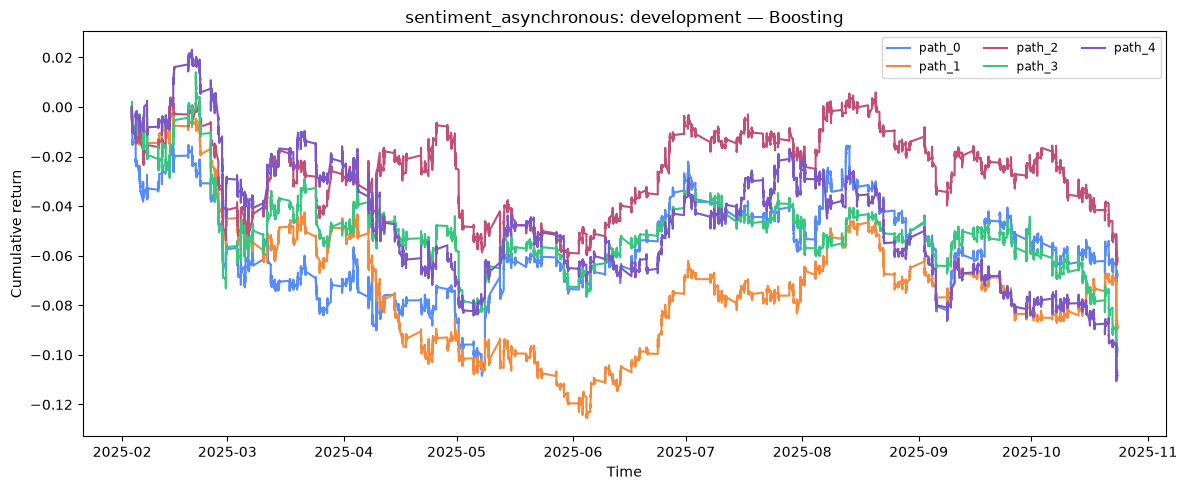

### Bagging: Backtest Statistics

path_0  \
section                  metric                          unit                                           
general_characteristics  start                           timestamp   2025-02-03 14:30:00.009395+00:00   
                         end                             timestamp          2025-10-23 20:00:00+00:00   
                         average_aum                     USD                             93053.745933   
                         leverage                        ratio                               0.935038   
                         maximum_dollar_position_size    USD                            132177.826508   
                         ratio_of_longs                  ratio                               0.530505   
                         frequency_of_bets               count/year                       3447.342498   
                         average_holding_period          days                                1.562039   
                         annualized_turnover             ratio                             645.495305   
                         correlation_to_underlying       ratio                               0.165568   
performance              pnl                             USD                            -10620.385856   
                         annualized_rate_of_return       ratio                              -0.144772   
                         pnl_from_long_positions         USD                              -348.328322   
                         pnl_from_short_positions        USD                            -10272.057534   
                         hit_ratio                       ratio                               0.471111   
                         average_return_from_hits        ratio                               0.001376   
                         average_return_from_misses      ratio                              -0.001308   
runs                     hhi_positive_returns            ratio                               0.000834   
                         hhi_negative_returns            ratio                               0.000857   
                         hhi_time_between_bets           ratio                               0.003101   
                         percentile_drawdown             ratio                               0.110469   
                         percentile_time_under_water     years                               0.717944   
implementation_shortfall broker_fees_per_turnover        ratio                                 0.0001   
                         average_slippage_per_turnover   ratio                                 0.0001   
                         dollar_performance_per_turnover ratio                              -0.000246   
                         return_on_execution_costs       ratio                              -1.231381   
efficiency               sharpe_ratio                    ratio                              -0.095385   
                         annualized_sharpe_ratio         ratio                              -1.822947   
                         probabilistic_sharpe_ratio      ratio                               0.008326   
classification_scores    primary_accuracy                score                               0.598717   
                         primary_precision               score                               0.588495   
                         primary_recall                  score                               0.719466   
                         primary_f1_score                score                               0.647423   
                         primary_negative_log_loss       score                              -0.656712   
                         meta_accuracy                   score                               0.597895   
                         meta_precision                  score                               0.600693   
                         meta_recall                     score                               0.979516   


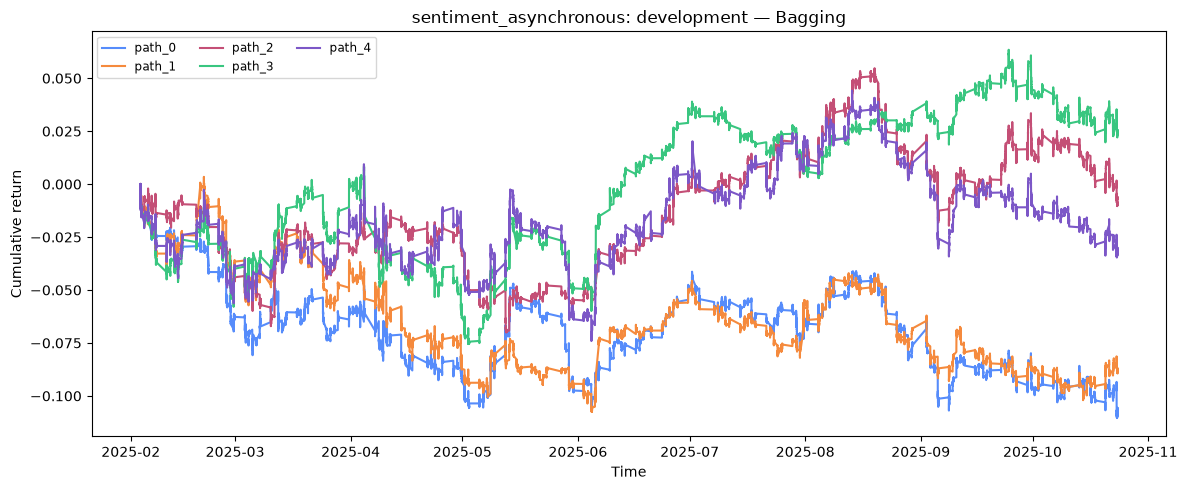

### Random Forest: Backtest Statistics

path_0  \
section                  metric                          unit                                           
general_characteristics  start                           timestamp   2025-02-03 14:30:00.009395+00:00   
                         end                             timestamp          2025-10-23 20:00:00+00:00   
                         average_aum                     USD                            104172.645638   
                         leverage                        ratio                               0.825997   
                         maximum_dollar_position_size    USD                            163866.060896   
                         ratio_of_longs                  ratio                               0.558502   
                         frequency_of_bets               count/year                       2678.480656   
                         average_holding_period          days                                1.124912   
                         annualized_turnover             ratio                             711.838954   
                         correlation_to_underlying       ratio                              -0.121254   
performance              pnl                             USD                              6100.888151   
                         annualized_rate_of_return       ratio                               0.085983   
                         pnl_from_long_positions         USD                              5945.485123   
                         pnl_from_short_positions        USD                               155.403027   
                         hit_ratio                       ratio                                 0.4961   
                         average_return_from_hits        ratio                                0.00192   
                         average_return_from_misses      ratio                              -0.001821   
runs                     hhi_positive_returns            ratio                               0.001326   
                         hhi_negative_returns            ratio                               0.001554   
                         hhi_time_between_bets           ratio                               0.004354   
                         percentile_drawdown             ratio                               0.018423   
                         percentile_time_under_water     years                               0.013403   
implementation_shortfall broker_fees_per_turnover        ratio                                 0.0001   
                         average_slippage_per_turnover   ratio                                 0.0001   
                         dollar_performance_per_turnover ratio                               0.000115   
                         return_on_execution_costs       ratio                               0.572977   
efficiency               sharpe_ratio                    ratio                               0.022131   
                         annualized_sharpe_ratio         ratio                               0.422954   
                         probabilistic_sharpe_ratio      ratio                               0.311618   
classification_scores    primary_accuracy                score                               0.598717   
                         primary_precision               score                               0.588495   
                         primary_recall                  score                               0.719466   
                         primary_f1_score                score                               0.647423   
                         primary_negative_log_loss       score                              -0.656712   
                         meta_accuracy                   score                                0.57676   
                         meta_precision                  score                               0.700635   
                         meta_recall                     score                               0.511745   


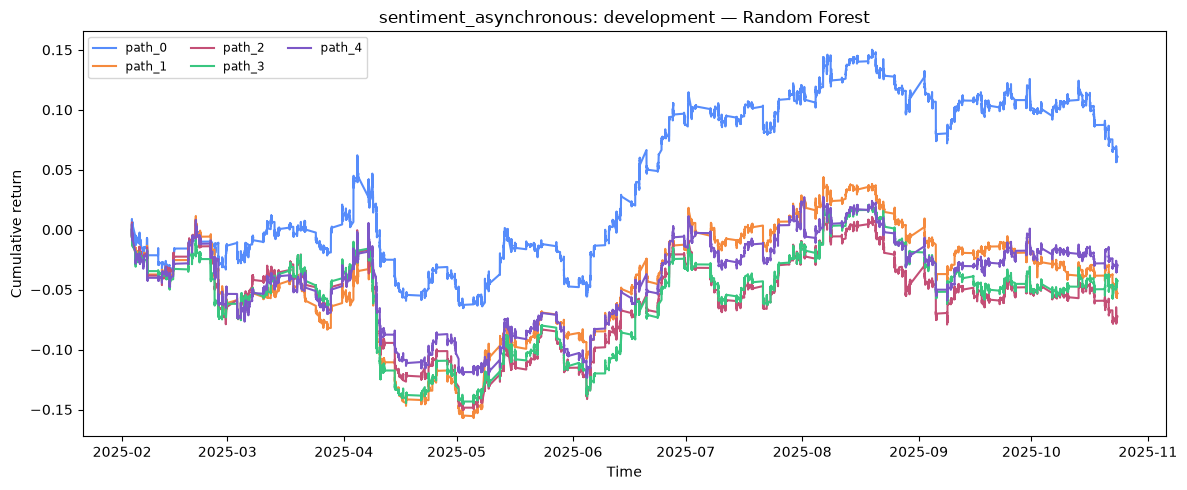

In [7]:
from IPython.display import Markdown

statistics_sections = (
    "general_characteristics", "performance", "runs",
    "implementation_shortfall", "efficiency", "classification_scores",
)
row_index = ["section", "metric", "unit"]

for family in ("boosting", "bagging", "random_forest"):
    family_name = family.replace("_", " ").title()
    family_statistics = statistics.loc[
        statistics["model_family"].eq(family) & statistics["section"].isin(statistics_sections)
    ].sort_values(
        "section", key=lambda values: values.map(statistics_sections.index), kind="stable",
    ).assign(
        metric=lambda frame: frame["metric"].where(
            frame["section"].ne("classification_scores"),
            frame["entity"] + "_" + frame["metric"],
        )
    )
    display_values = family_statistics["value"].astype(object).where(
        family_statistics["unit"].ne("timestamp"), family_statistics["timestamp"],
    )
    display(Markdown(f"### {family_name}: Backtest Statistics"))
    with pd.option_context(
        "display.max_rows", None, "display.max_columns", None,
        "display.max_colwidth", None,
    ):
        display(family_statistics.assign(display_value=display_values).pivot(
            index=row_index, columns="path",
            values="display_value",
        ).reindex(
            pd.MultiIndex.from_frame(family_statistics[row_index].drop_duplicates())
        ).rename_axis(columns=None))

    fig, ax = plt.subplots(figsize=(12, 5))
    for (account_family, path), result in accounts.items():
        if account_family == family:
            ledger = result["ledger"]
            ax.plot(ledger.timestamp, ledger.aum / settings.initial_aum - 1, label=path)
    ax.set(
        title=f"{STRATEGY}: {PARTITION} — {family_name}",
        ylabel="Cumulative return", xlabel="Time",
    )
    ax.legend(fontsize="small", ncol=3)
    fig.tight_layout()
    plt.show()

In [8]:
result_directory = save_backtest_results(
    inputs, statistics, accounts,
    evaluation_settings=evaluation_settings, validation_settings=validation_settings,
)
print(result_directory)

/Users/kwonjunhyuk9/Documents/financial-machine-learning/data/backtesting/sentiment_asynchronous/development
